# External AI incident severity

Quantify Case Competition 2026 · Team Analysts

135 external incident estimates are severity evidence, not a TSI claim-frequency dataset. The notebook requires the authorized combined workbook. No row-level descriptions are exported.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / "src" / "analysis.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


In [2]:
from src.analysis import load_exhibits, severity_summary, candidate_subset, model_diagnostics, sequential_shares
_, incidents = load_exhibits()
assert len(incidents) == 135
assert not incidents.incident_id.duplicated().any()
print(f"Valid incident IDs: {len(incidents)}")
display(incidents.estimated_insured_loss_cad.describe(percentiles=[.5,.9,.95]))
display(severity_summary(incidents, ["failure_type"]).sort_values("mean_cad", ascending=False))

Valid incident IDs: 135


count          135.0000
mean     3,304,222.2222
std      5,110,203.6056
min         55,000.0000
50%      2,079,000.0000
90%      5,887,800.0000
95%     14,377,800.0000
max     31,173,000.0000
Name: estimated_insured_loss_cad, dtype: float64

,failure_type,n,mean_cad,median_cad,minimum_cad,maximum_cad,total_cad
1,Autonomous System Failure,9,"19,901,777.7778","16,454,000.0000",12887000,31173000,179116000
5,Privacy and Security,28,"4,119,928.5714","4,084,500.0000",1587000,7005000,115358000
2,Cyber Exploitation via AI,17,"3,671,470.5882","3,592,000.0000",2067000,7357000,62415000
0,Algorithmic Bias,26,"2,792,230.7692","2,541,500.0000",1038000,5294000,72598000
4,Misinformation,19,"585,263.1579","652,000.0000",141000,1190000,11120000
3,Hallucinated Output,36,"151,750.0000","157,000.0000",55000,289000,5463000


Top-nine loss share: 40.15%
Top-nine mechanisms: Autonomous System Failure
1.5×IQR threshold: CAD 9,423,500; observations above: 9


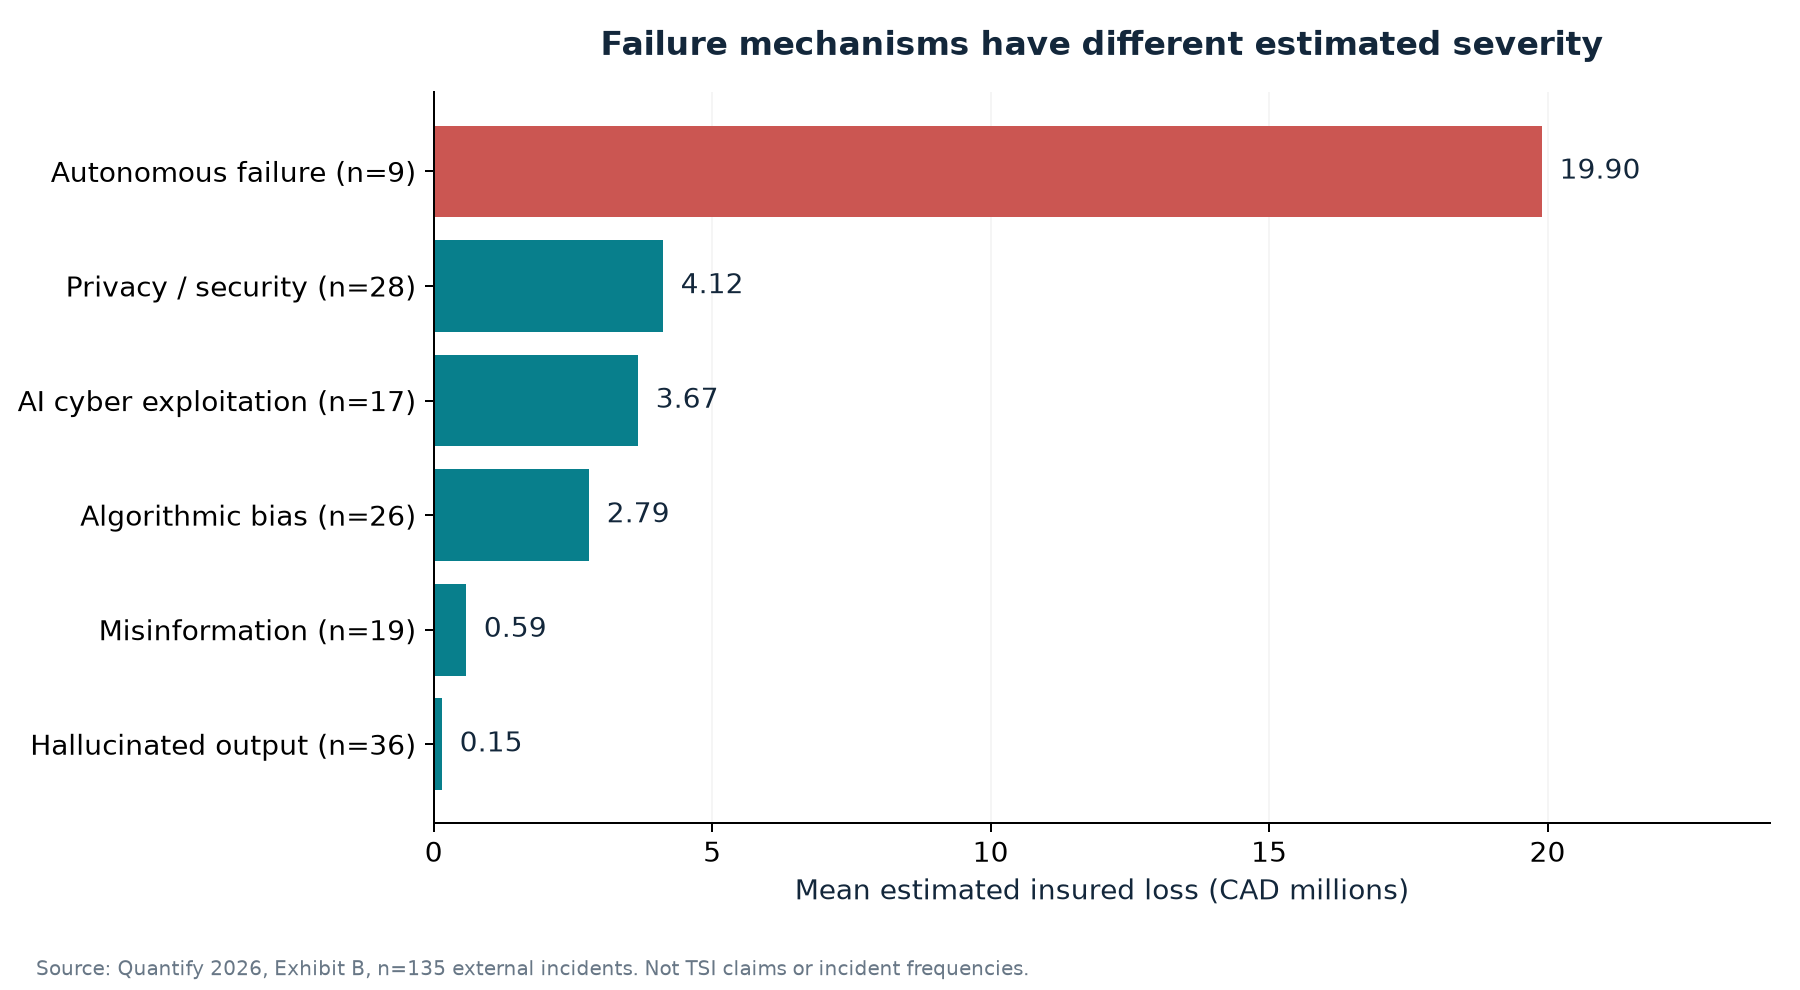

In [3]:
top = incidents.nlargest(9, "estimated_insured_loss_cad")
print(f"Top-nine loss share: {top.estimated_insured_loss_cad.sum()/incidents.estimated_insured_loss_cad.sum():.2%}")
print(f"Top-nine mechanisms: {', '.join(top.failure_type.unique())}")
q1, q3 = incidents.estimated_insured_loss_cad.quantile([.25,.75])
cutoff = q3 + 1.5*(q3-q1)
print(f"1.5×IQR threshold: CAD {cutoff:,.0f}; observations above: {(incidents.estimated_insured_loss_cad>cutoff).sum()}")
display(Image(filename=str(ROOT / "figures/severity-by-failure-type.png")))

## Candidate group before coverage mapping

Supervised hallucination and misinformation form a smaller descriptive group. Bodily injury, IP, penalties, insured roles and policy exclusions still require event-level mapping. Its mean is not an automatically usable insured payout estimate.

In [4]:
candidate = candidate_subset(incidents)
display(severity_summary(candidate, ["failure_type"]))
print(f"Candidate count: {len(candidate)}")
print(f"Candidate average estimated loss: CAD {candidate.estimated_insured_loss_cad.mean():,.0f}")
print(f"Candidate observed maximum: CAD {candidate.estimated_insured_loss_cad.max():,.0f}")

,failure_type,n,mean_cad,median_cad,minimum_cad,maximum_cad,total_cad
0,Hallucinated Output,22,"145,181.8182","161,500.0000",55000,210000,3194000
1,Misinformation,6,"250,000.0000","256,000.0000",141000,342000,1500000


Candidate count: 28
Candidate average estimated loss: CAD 167,643
Candidate observed maximum: CAD 342,000


## Oversight: association, denominators and adjustment

The raw arithmetic comparison, adjusted geometric-mean ratio and reverse-denominator percentage are distinct. An oversight flag does not establish causal prevention, effective review or low autonomy.

In [5]:
groups = severity_summary(incidents, ["human_oversight"]).set_index("human_oversight")
display(groups)
yes, no = groups.loc["Yes","mean_cad"], groups.loc["No","mean_cad"]
print(f"Oversight group lower than no-oversight group: {1-yes/no:.2%}")
print(f"No-oversight group higher than oversight group: {no/yes-1:.2%}")
model, unique = model_diagnostics(incidents)
print(f"Adjusted oversight log coefficient: {model['oversight_log_coefficient']:.5f}")
print(f"Conditional geometric-mean ratio: {model['oversight_conditional_geometric_mean_ratio']:.5f}")
print(f"Autonomous-failure incidents with oversight: {len(incidents[(incidents.failure_type=='Autonomous System Failure') & (incidents.human_oversight=='Yes')])}")

,n,mean_cad,median_cad,minimum_cad,maximum_cad,total_cad
human_oversight,,,,,,
No,67,"4,226,522.3881","2,803,000.0000",73000,31173000,283177000
Yes,68,"2,395,485.2941","1,874,500.0000",55000,16443000,162893000


Oversight group lower than no-oversight group: 43.32%
No-oversight group higher than oversight group: 76.44%
Adjusted oversight log coefficient: -0.42975
Conditional geometric-mean ratio: 0.65067
Autonomous-failure incidents with oversight: 4


## Sequential ANOVA attribution depends on order

Industry and failure mechanism share information. Sequential shares add to the same fit, but do not identify independent causal contributions. Unique contributions condition on the other factors and need not sum to R².

,order,term,share_of_total_log_variance
0,"industry, failure_type, human_oversight",industry,0.2224
1,"industry, failure_type, human_oversight",failure_type,0.7114
2,"industry, failure_type, human_oversight",human_oversight,0.0163
3,"industry, failure_type, human_oversight",Residual,0.0499
4,"failure_type, industry, human_oversight",failure_type,0.9306
5,"failure_type, industry, human_oversight",industry,0.0032
6,"failure_type, industry, human_oversight",human_oversight,0.0163
7,"failure_type, industry, human_oversight",Residual,0.0499


,term,unique_share_of_total_log_variance
0,industry,0.0027
1,failure_type,0.6531
2,human_oversight,0.0163


R-squared on log loss: 95.009%
Adjusted R-squared: 94.518%
Random five-fold log-loss R-squared: 93.595%


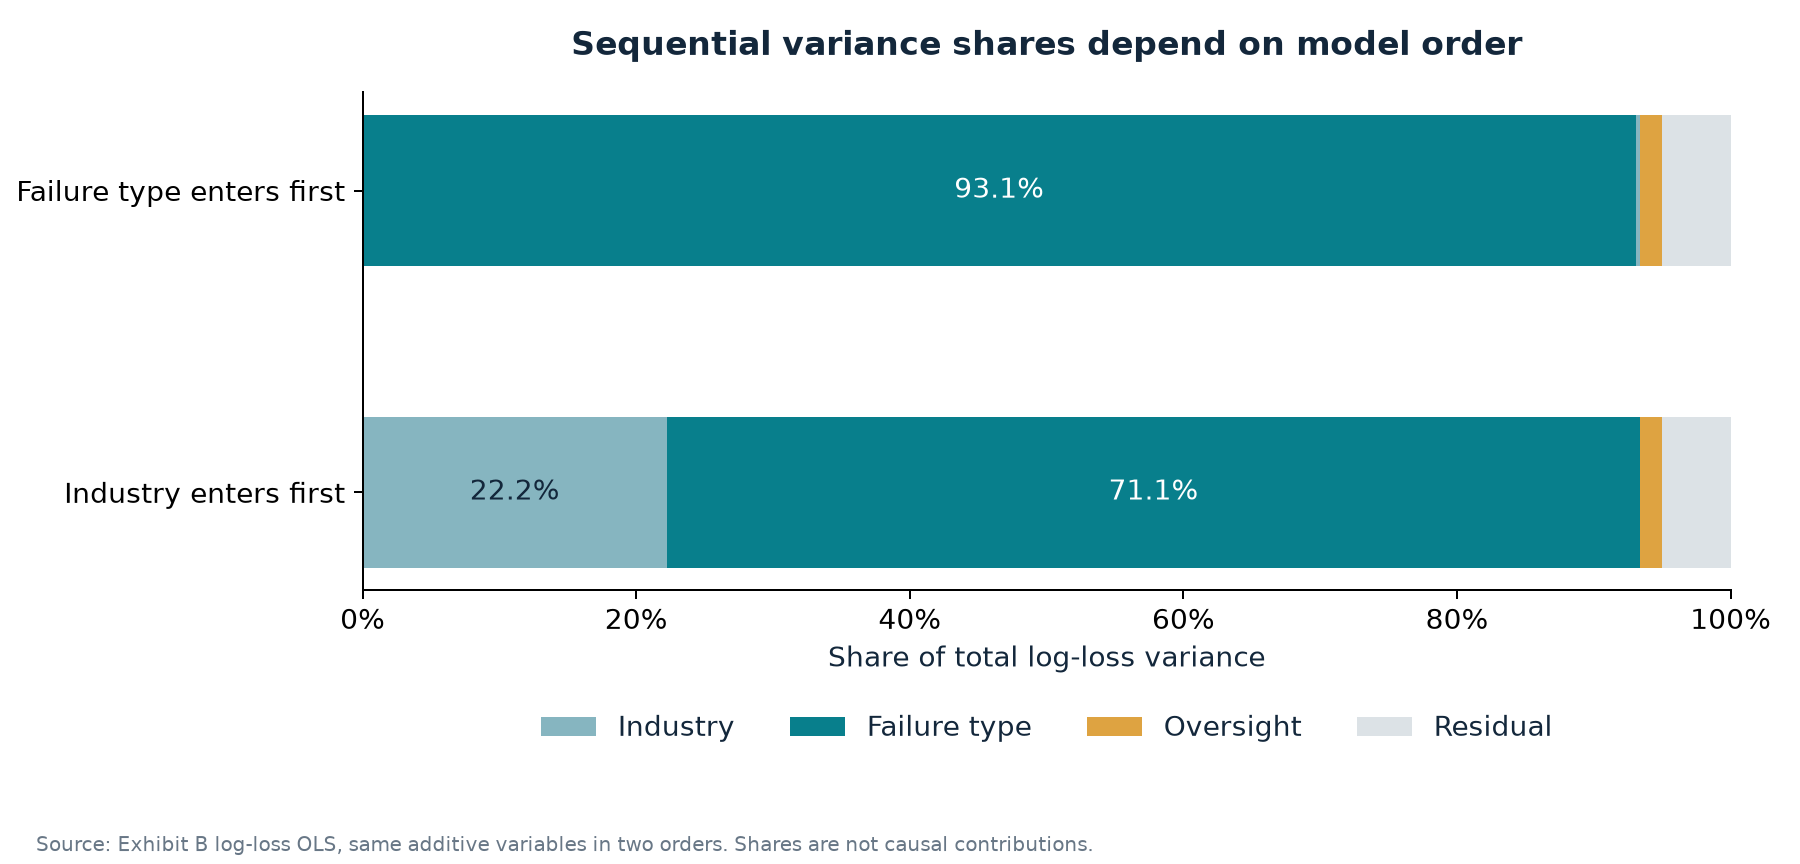

In [6]:
original = sequential_shares(incidents, ["industry", "failure_type", "human_oversight"])
alternative = sequential_shares(incidents, ["failure_type", "industry", "human_oversight"])
display(pd.concat([original, alternative], ignore_index=True))
display(unique)
print(f"R-squared on log loss: {model['r_squared']:.3%}")
print(f"Adjusted R-squared: {model['adjusted_r_squared']:.3%}")
print(f"Random five-fold log-loss R-squared: {model['random_five_fold_log_r_squared']:.3%}")
display(Image(filename=str(ROOT / "figures/model-order-sensitivity.png")))

## Interpretation limits

Random folds check patterns within this selected dataset. They do not test temporal change, new populations, independent event templates, causal effects or future insured losses. A high log-loss R² cannot establish a rate, a premium discount, an annual incident frequency or sufficient capital. AIID/CSET and DAIL historical percentages are omitted because their original extracts were not supplied.